# ResNet18 — Transfer Learning for Distracted Driver Detection

## 1. Experiment Setup

### Objective
Fine-tune an ImageNet-pretrained ResNet18 to classify
10 distracted-driving activities.

### Dataset
- Training: 15,732 images from 18 drivers
- Validation: 3,603 images from 4 unseen drivers
- Final test: Reserved for final evaluation

### Configuration
- Architecture: ResNet18
- Pretrained weights: ImageNet
- Input resolution: 256×192 RGB
- Number of classes: 10
- Evaluation: Accuracy, Macro-F1, confusion matrix
- Save: Checkpoints, training history, hyperparameters, runtimes

### Research Question
Can transfer learning improve generalization compared with
our CNN trained entirely from scratch?

In [1]:
# ==========================================
# 1. Import libraries
# ==========================================

import torch
import torch.nn as nn
import torchvision
import pandas as pd
import numpy as np
import random

from pathlib import Path
from PIL import Image
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader

# ==========================================
# 2. Experiment configuration
# ==========================================

ROOT = Path("..")

SEED = 42

IMAGE_WIDTH = 256
IMAGE_HEIGHT = 192

BATCH_SIZE = 32

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

# ==========================================
# 3. Load existing driver-based splits
# ==========================================

train_df = pd.read_csv(
    ROOT / "data/splits/driver_based/train.csv"
)

val_df = pd.read_csv(
    ROOT / "data/splits/driver_based/val.csv"
)

image_root = ROOT / "data/raw/imgs/train"

# ==========================================
# 4. Verify datasets
# ==========================================

assert image_root.exists()

assert set(train_df["subject"]).isdisjoint(
    set(val_df["subject"])
)

print("\nTraining images:", len(train_df))
print("Training drivers:", train_df["subject"].nunique())

print("\nValidation images:", len(val_df))
print("Validation drivers:", val_df["subject"].nunique())

print("\nImage resolution:", IMAGE_WIDTH, "x", IMAGE_HEIGHT)

print("\nDataset verification successful!")

Device: cuda
PyTorch: 2.14.1+cu132
Torchvision: 0.29.1+cu132

Training images: 15732
Training drivers: 18

Validation images: 3603
Validation drivers: 4

Image resolution: 256 x 192

Dataset verification successful!


## 2. Image Preprocessing and DataLoaders

Prepare the dataset for ImageNet-pretrained ResNet18.

- Resize images to 256×192.
- Apply mild augmentation to training images only.
- Normalize RGB channels using ImageNet statistics.
- Keep validation images free from random augmentation.
- Use batch size 32.
- Maintain driver-independent training and validation splits.

In [2]:
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# ==========================================
# 1. ImageNet normalization
# ==========================================

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


# ==========================================
# 2. Training preprocessing
# ==========================================

train_transform = transforms.Compose([

    transforms.Resize((IMAGE_HEIGHT, IMAGE_WIDTH)),

    # Mild augmentation
    transforms.RandomAffine(
        degrees=5,
        translate=(0.04, 0.04),
        scale=(0.97, 1.03),
        interpolation=InterpolationMode.BILINEAR
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    # Required normalization for pretrained ResNet18
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ==========================================
# 3. Validation preprocessing
# ==========================================

val_transform = transforms.Compose([

    transforms.Resize((IMAGE_HEIGHT, IMAGE_WIDTH)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ==========================================
# 4. Custom Dataset
# ==========================================

class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):

        row = self.data.iloc[idx]

        image_path = (
            image_root /
            row["classname"] /
            row["img"]
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        # Convert c0-c9 to integer labels 0-9
        label = int(row["classname"][1:])

        return image, label


# ==========================================
# 5. Create datasets
# ==========================================

train_dataset = DriverDataset(
    train_df,
    train_transform
)

val_dataset = DriverDataset(
    val_df,
    val_transform
)


# ==========================================
# 6. Create DataLoaders
# ==========================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


# ==========================================
# 7. Verify
# ==========================================

images, labels = next(iter(train_loader))

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("\nBatch shape:", images.shape)
print("Labels shape:", labels.shape)

print("\nImageNet normalization applied!")
print("ResNet18 DataLoaders ready!")

Training images: 15732
Validation images: 3603

Batch shape: torch.Size([32, 3, 192, 256])
Labels shape: torch.Size([32])

ImageNet normalization applied!
ResNet18 DataLoaders ready!


## 3. Load Pretrained ResNet18

Load ResNet18 pretrained on ImageNet.

- Use pretrained weights to initialize the network.
- Replace the original 1,000-class classifier with 10 outputs.
- Allow all layers to be fine-tuned.
- Verify the model's parameters and output dimensions.

Goal: Transfer learned visual representations to distracted-driver detection.

In [3]:
import torch
import torch.nn as nn
from torchvision import models

# ==========================================
# 1. Load ImageNet-pretrained ResNet18
# ==========================================

weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# ==========================================
# 2. Replace the classification layer
# ==========================================

# Original classifier: 512 -> 1000 classes
print("Original classifier:", model.fc)

# New classifier: 512 -> 10 driving classes
model.fc = nn.Linear(
    in_features=model.fc.in_features,
    out_features=10
)

# ==========================================
# 3. Move model to GPU
# ==========================================

model = model.to(device)

# Allow all layers to be fine-tuned
for param in model.parameters():
    param.requires_grad = True

# ==========================================
# 4. Count parameters
# ==========================================

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nNew classifier:", model.fc)

print(f"\nTotal parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# ==========================================
# 5. Verify forward pass
# ==========================================

model.eval()

with torch.no_grad():

    # Use only 2 images for verification
    sample_images = images[:2].to(device)

    outputs = model(sample_images)

print("\nInput shape:", sample_images.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (2, 10)

print("\nPretrained ResNet18 ready!")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/js/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 113MB/s]


Original classifier: Linear(in_features=512, out_features=1000, bias=True)

New classifier: Linear(in_features=512, out_features=10, bias=True)

Total parameters: 11,181,642
Trainable parameters: 11,181,642

Input shape: torch.Size([2, 3, 192, 256])
Output shape: torch.Size([2, 10])

Pretrained ResNet18 ready!


## 4. ResNet18 — Full Fine-Tuning

### Objective
Fine-tune ImageNet-pretrained ResNet18 for distracted-driver
classification using all 18 training drivers.

### Configuration
- Architecture: ResNet18 (ImageNet pretrained)
- Training images: 15,732
- Validation images: 3,603
- Resolution: 256×192 RGB
- Trainable parameters: 11,181,642
- Optimizer: AdamW
- Backbone learning rate: 0.0001
- Classifier learning rate: 0.001
- Weight decay: 0.0001
- Batch size: 32
- Maximum epochs: 15
- Minimum epochs: 7
- Early stopping patience: 5
- Best checkpoint: Highest validation Macro-F1

### Evaluation
Record training loss, training accuracy, validation loss,
validation accuracy, validation Macro-F1, and execution times.

The final test dataset remains untouched.

In [4]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import time
import json

from sklearn.metrics import f1_score


# ============================================================
# 1. CONFIGURATION
# ============================================================

MAX_EPOCHS = 15
MIN_EPOCHS = 7
PATIENCE = 5

BACKBONE_LR = 0.0001
CLASSIFIER_LR = 0.001
WEIGHT_DECAY = 0.0001

criterion = nn.CrossEntropyLoss()


# ============================================================
# 2. OPTIMIZER — DIFFERENT LEARNING RATES
# ============================================================

# Pretrained ResNet18 layers
backbone_params = [
    param
    for name, param in model.named_parameters()
    if not name.startswith("fc.")
]

# New classification layer
classifier_params = list(model.fc.parameters())

optimizer = torch.optim.AdamW(
    [
        {
            "params": backbone_params,
            "lr": BACKBONE_LR
        },
        {
            "params": classifier_params,
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

print("Backbone learning rate:", BACKBONE_LR)
print("Classifier learning rate:", CLASSIFIER_LR)
print("Optimizer: AdamW")


# ============================================================
# 3. CREATE EXPERIMENT DIRECTORIES
# ============================================================

exp_dir = (
    ROOT / "results/deep_learning/driver_based/"
    "resnet18/full_finetuning"
)

model_dir = (
    ROOT / "models/deep_learning/driver_based/"
    "resnet18/full_finetuning"
)

exp_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)

best_model_path = model_dir / "best_model.pt"

history_path = exp_dir / "training_history.csv"
results_path = exp_dir / "results.json"
config_path = exp_dir / "configuration.json"


# ============================================================
# 4. SAVE CONFIGURATION
# ============================================================

config = {
    "model": "ResNet18",
    "pretrained": True,
    "pretrained_dataset": "ImageNet",
    "fine_tuning": "all_layers",

    "resolution": [IMAGE_WIDTH, IMAGE_HEIGHT],

    "training_images": len(train_dataset),
    "validation_images": len(val_dataset),

    "batch_size": BATCH_SIZE,

    "optimizer": "AdamW",
    "backbone_lr": BACKBONE_LR,
    "classifier_lr": CLASSIFIER_LR,
    "weight_decay": WEIGHT_DECAY,

    "max_epochs": MAX_EPOCHS,
    "min_epochs": MIN_EPOCHS,
    "patience": PATIENCE,

    "checkpoint_selection": "validation_macro_f1",

    "seed": SEED,
    "device": str(device)
}

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)


# ============================================================
# 5. TRAINING PREPARATION
# ============================================================

history = []

best_f1 = -1.0
best_epoch = 0
best_accuracy = 0.0

epochs_without_improvement = 0

if device.type == "cuda":
    torch.cuda.synchronize()

start_total = time.perf_counter()


# ============================================================
# 6. MAIN TRAINING LOOP
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):

    # --------------------------------------------------------
    # A. TRAINING
    # --------------------------------------------------------

    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_train = time.perf_counter()

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation through ALL ResNet18 layers
        loss.backward()

        # Update weights
        optimizer.step()

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += batch_size

    if device.type == "cuda":
        torch.cuda.synchronize()

    train_time = time.perf_counter() - start_train

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total


    # --------------------------------------------------------
    # B. VALIDATION
    # --------------------------------------------------------

    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    all_true = []
    all_pred = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_val = time.perf_counter()

    # No weight updates during validation
    with torch.inference_mode():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            predictions = outputs.argmax(dim=1)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += batch_size

            all_true.extend(
                labels.cpu().tolist()
            )

            all_pred.extend(
                predictions.cpu().tolist()
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    val_time = time.perf_counter() - start_val


    # --------------------------------------------------------
    # C. CALCULATE METRICS
    # --------------------------------------------------------

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    val_macro_f1 = f1_score(
        all_true,
        all_pred,
        labels=list(range(10)),
        average="macro",
        zero_division=0
    )

    epoch_time = train_time + val_time


    # --------------------------------------------------------
    # D. SAVE TRAINING HISTORY
    # --------------------------------------------------------

    history.append({
        "epoch": epoch,

        "train_loss": float(train_loss),
        "train_accuracy": float(train_accuracy),

        "val_loss": float(val_loss),
        "val_accuracy": float(val_accuracy),
        "val_macro_f1": float(val_macro_f1),

        "train_time_seconds": float(train_time),
        "val_time_seconds": float(val_time),
        "epoch_time_seconds": float(epoch_time)
    })

    pd.DataFrame(history).to_csv(
        history_path,
        index=False
    )


    # --------------------------------------------------------
    # E. SAVE BEST MODEL
    # --------------------------------------------------------

    improved = val_macro_f1 > best_f1 + 1e-4

    if improved:

        best_f1 = float(val_macro_f1)
        best_accuracy = float(val_accuracy)
        best_epoch = epoch

        torch.save(
            model.state_dict(),
            best_model_path
        )


    # --------------------------------------------------------
    # F. DISPLAY EPOCH RESULTS
    # --------------------------------------------------------

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_macro_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {epoch_time:.1f}s",
        flush=True
    )


    # --------------------------------------------------------
    # G. EARLY STOPPING
    # --------------------------------------------------------

    if epoch <= MIN_EPOCHS:

        epochs_without_improvement = 0

    else:

        if improved:
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:

            print(
                f"\nEarly stopping at epoch {epoch}"
            )

            break


# ============================================================
# 7. TOTAL EXECUTION TIME
# ============================================================

if device.type == "cuda":
    torch.cuda.synchronize()

total_time = time.perf_counter() - start_total


# ============================================================
# 8. SAVE FINAL RESULTS
# ============================================================

history_df = pd.DataFrame(history)

best_record = history_df[
    history_df["epoch"] == best_epoch
].iloc[0]

results = {
    "model": "ResNet18",
    "fine_tuning": "all_layers",

    "epochs_completed": len(history),
    "best_epoch": int(best_epoch),

    "best_val_accuracy": float(best_accuracy),
    "best_val_macro_f1": float(best_f1),
    "best_val_loss": float(best_record["val_loss"]),

    "total_training_seconds": float(total_time),

    "best_checkpoint": str(best_model_path),
    "training_history": str(history_path)
}

with open(results_path, "w") as f:
    json.dump(results, f, indent=4)


# ============================================================
# 9. RESTORE BEST MODEL
# ============================================================

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()


# ============================================================
# 10. DISPLAY SUMMARY
# ============================================================

print("\n" + "=" * 50)
print("RESNET18 — FULL FINE-TUNING COMPLETED")
print("=" * 50)

print("Epochs completed:", len(history))
print("Best epoch:", best_epoch)

print(
    f"\nBest validation accuracy: "
    f"{best_accuracy:.4f}"
)

print(
    f"Best validation Macro-F1: "
    f"{best_f1:.4f}"
)

print(
    f"\nTotal execution time: "
    f"{total_time:.2f} seconds"
)

print("\nModel saved:", best_model_path)
print("History saved:", history_path)
print("Results saved:", results_path)

Backbone learning rate: 0.0001
Classifier learning rate: 0.001
Optimizer: AdamW
Epoch 01/15 | Train Acc: 0.9497 | Val Acc: 0.7949 | Val F1: 0.7958 | Val Loss: 0.5468 | Time: 56.5s
Epoch 02/15 | Train Acc: 0.9936 | Val Acc: 0.8049 | Val F1: 0.7808 | Val Loss: 0.8255 | Time: 56.7s
Epoch 03/15 | Train Acc: 0.9935 | Val Acc: 0.8701 | Val F1: 0.8573 | Val Loss: 0.4363 | Time: 56.8s
Epoch 04/15 | Train Acc: 0.9938 | Val Acc: 0.8052 | Val F1: 0.7985 | Val Loss: 0.7933 | Time: 57.2s
Epoch 05/15 | Train Acc: 0.9969 | Val Acc: 0.8893 | Val F1: 0.8819 | Val Loss: 0.4439 | Time: 57.7s
Epoch 06/15 | Train Acc: 0.9959 | Val Acc: 0.8546 | Val F1: 0.8416 | Val Loss: 0.5508 | Time: 57.4s
Epoch 07/15 | Train Acc: 0.9971 | Val Acc: 0.8837 | Val F1: 0.8692 | Val Loss: 0.4980 | Time: 56.6s
Epoch 08/15 | Train Acc: 0.9966 | Val Acc: 0.8709 | Val F1: 0.8624 | Val Loss: 0.5128 | Time: 57.6s
Epoch 09/15 | Train Acc: 0.9981 | Val Acc: 0.8626 | Val F1: 0.8534 | Val Loss: 0.5115 | Time: 57.8s
Epoch 10/15 | Train 

## 5. ResNet18 — Validation Inference and Error Analysis

Evaluate the best ResNet18 checkpoint on four unseen drivers.

Objectives:
- Verify validation accuracy and Macro-F1.
- Generate a normalized confusion matrix.
- Identify difficult classes.
- Measure driver-specific classification accuracy.
- Compare errors against CNN V3.

RESNET18 — VALIDATION RESULTS
Validation images: 3603
Accuracy: 0.8893
Macro-F1: 0.8819

PER-CLASS CLASSIFICATION REPORT
              precision    recall  f1-score   support

          c0       0.86      0.65      0.74       372
          c1       0.98      0.88      0.93       377
          c2       0.95      0.99      0.97       367
          c3       0.98      0.96      0.97       393
          c4       0.97      0.97      0.97       378
          c5       0.97      0.99      0.98       372
          c6       0.78      0.99      0.87       372
          c7       0.95      0.98      0.96       342
          c8       0.63      0.65      0.64       298
          c9       0.79      0.78      0.78       332

    accuracy                           0.89      3603
   macro avg       0.89      0.88      0.88      3603
weighted avg       0.89      0.89      0.89      3603



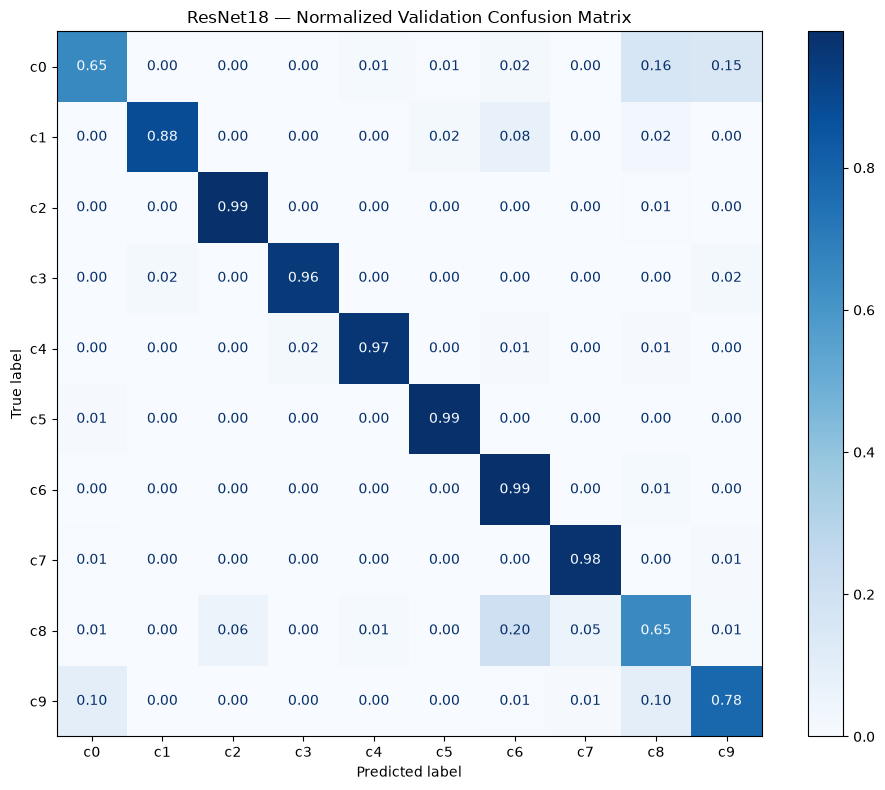


ACCURACY BY DRIVER
         images  accuracy
subject                  
p014        876  0.851598
p075        814  0.859951
p016       1078  0.914657
p047        835  0.924551

Error analysis saved!


In [5]:
import torch
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. Load best ResNet18 checkpoint
# ==========================================

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

# ==========================================
# 2. Run inference
# ==========================================

y_true = []
y_pred = []

with torch.inference_mode():

    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())


# ==========================================
# 3. Calculate metrics
# ==========================================

accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    labels=list(range(10)),
    zero_division=0
)

print("RESNET18 — VALIDATION RESULTS")
print("=" * 45)

print("Validation images:", len(y_true))
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")

print("\nPER-CLASS CLASSIFICATION REPORT")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(10)),
        target_names=[f"c{i}" for i in range(10)],
        zero_division=0
    )
)


# ==========================================
# 4. Normalized confusion matrix
# ==========================================

analysis_dir = exp_dir / "error_analysis"
analysis_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(10)),
    display_labels=[f"c{i}" for i in range(10)],
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    ax=ax
)

ax.set_title(
    "ResNet18 — Normalized Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    analysis_dir / "confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==========================================
# 5. Driver-specific accuracy
# ==========================================

prediction_df = val_df.reset_index(drop=True).copy()

assert len(prediction_df) == len(y_true)

assert (
    prediction_df["classname"]
    .str[1:]
    .astype(int)
    .tolist()
    == y_true
)

prediction_df["predicted"] = [
    f"c{x}" for x in y_pred
]

prediction_df["correct"] = [
    actual == predicted
    for actual, predicted in zip(y_true, y_pred)
]

driver_results = (
    prediction_df
    .groupby("subject")
    .agg(
        images=("correct", "size"),
        accuracy=("correct", "mean")
    )
    .sort_values("accuracy")
)

print("\nACCURACY BY DRIVER")
print(driver_results.to_string())


# ==========================================
# 6. Save predictions and results
# ==========================================

prediction_df.to_csv(
    analysis_dir / "validation_predictions.csv",
    index=False
)

driver_results.to_csv(
    analysis_dir / "driver_accuracy.csv"
)

print("\nError analysis saved!")

## 6. ResNet18 — Driver-Specific Error Analysis

Investigate whether transfer learning reduces the systematic
driver-specific classification errors observed in CNN V3.

Focus on three previously challenging cases:
- p075: c4 → c8
- p016: c9 → c4
- p047: c8 → c7

Calculate the percentage of images incorrectly classified
into each specific class.

In [6]:
# Driver-specific errors previously identified in CNN V3
cases = [
    ("p075", "c4", "c8"),
    ("p016", "c9", "c4"),
    ("p047", "c8", "c7")
]

comparison_results = []

for driver, actual, predicted in cases:

    # Select all images of this activity from this driver
    subset = prediction_df[
        (prediction_df["subject"] == driver) &
        (prediction_df["classname"] == actual)
    ]

    # Count images predicted as the incorrect class
    mistakes = (
        subset["predicted"] == predicted
    ).sum()

    # Percentage of this specific confusion
    error_rate = mistakes / len(subset) * 100

    comparison_results.append({
        "driver": driver,
        "actual": actual,
        "incorrect_prediction": predicted,
        "total_images": len(subset),
        "mistakes": int(mistakes),
        "error_rate_percent": round(error_rate, 2)
    })

comparison_df = pd.DataFrame(comparison_results)

print("RESNET18 — DRIVER-SPECIFIC ERROR ANALYSIS")
print("=" * 55)

print(comparison_df.to_string(index=False))

# Save results
comparison_df.to_csv(
    analysis_dir / "driver_specific_confusions.csv",
    index=False
)

RESNET18 — DRIVER-SPECIFIC ERROR ANALYSIS
driver actual incorrect_prediction  total_images  mistakes  error_rate_percent
  p075     c4                   c8            89         3                3.37
  p016     c9                   c4           120         0                0.00
  p047     c8                   c7            82         7                8.54


## 7. ResNet18 — Training and Validation Curves

Visualize training and validation accuracy and Macro-F1
across epochs.

Identify the best checkpoint and examine overfitting.

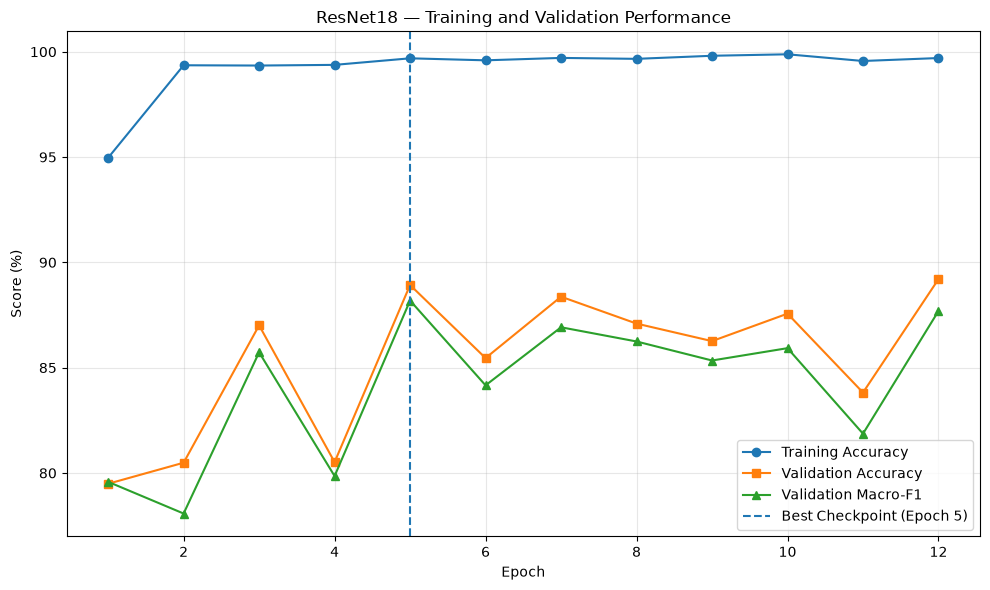

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Load saved training history
resnet_history = pd.read_csv(history_path)

plt.figure(figsize=(10, 6))

# Training accuracy
plt.plot(
    resnet_history["epoch"],
    resnet_history["train_accuracy"] * 100,
    marker="o",
    label="Training Accuracy"
)

# Validation accuracy
plt.plot(
    resnet_history["epoch"],
    resnet_history["val_accuracy"] * 100,
    marker="s",
    label="Validation Accuracy"
)

# Validation Macro-F1
plt.plot(
    resnet_history["epoch"],
    resnet_history["val_macro_f1"] * 100,
    marker="^",
    label="Validation Macro-F1"
)

# Mark best checkpoint
plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Checkpoint (Epoch {best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Score (%)")
plt.title("ResNet18 — Training and Validation Performance")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save for presentation
plt.savefig(
    exp_dir / "training_validation_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. ResNet18 — Random Validation Image Predictions

Randomly select images from the validation dataset and
perform inference using our fine-tuned ResNet18.

Display:
- Original image
- Actual driving activity
- Predicted driving activity
- Prediction confidence
- Whether the prediction was correct

Goal: Visually understand which driving activities
are easier or harder for the model to recognize.

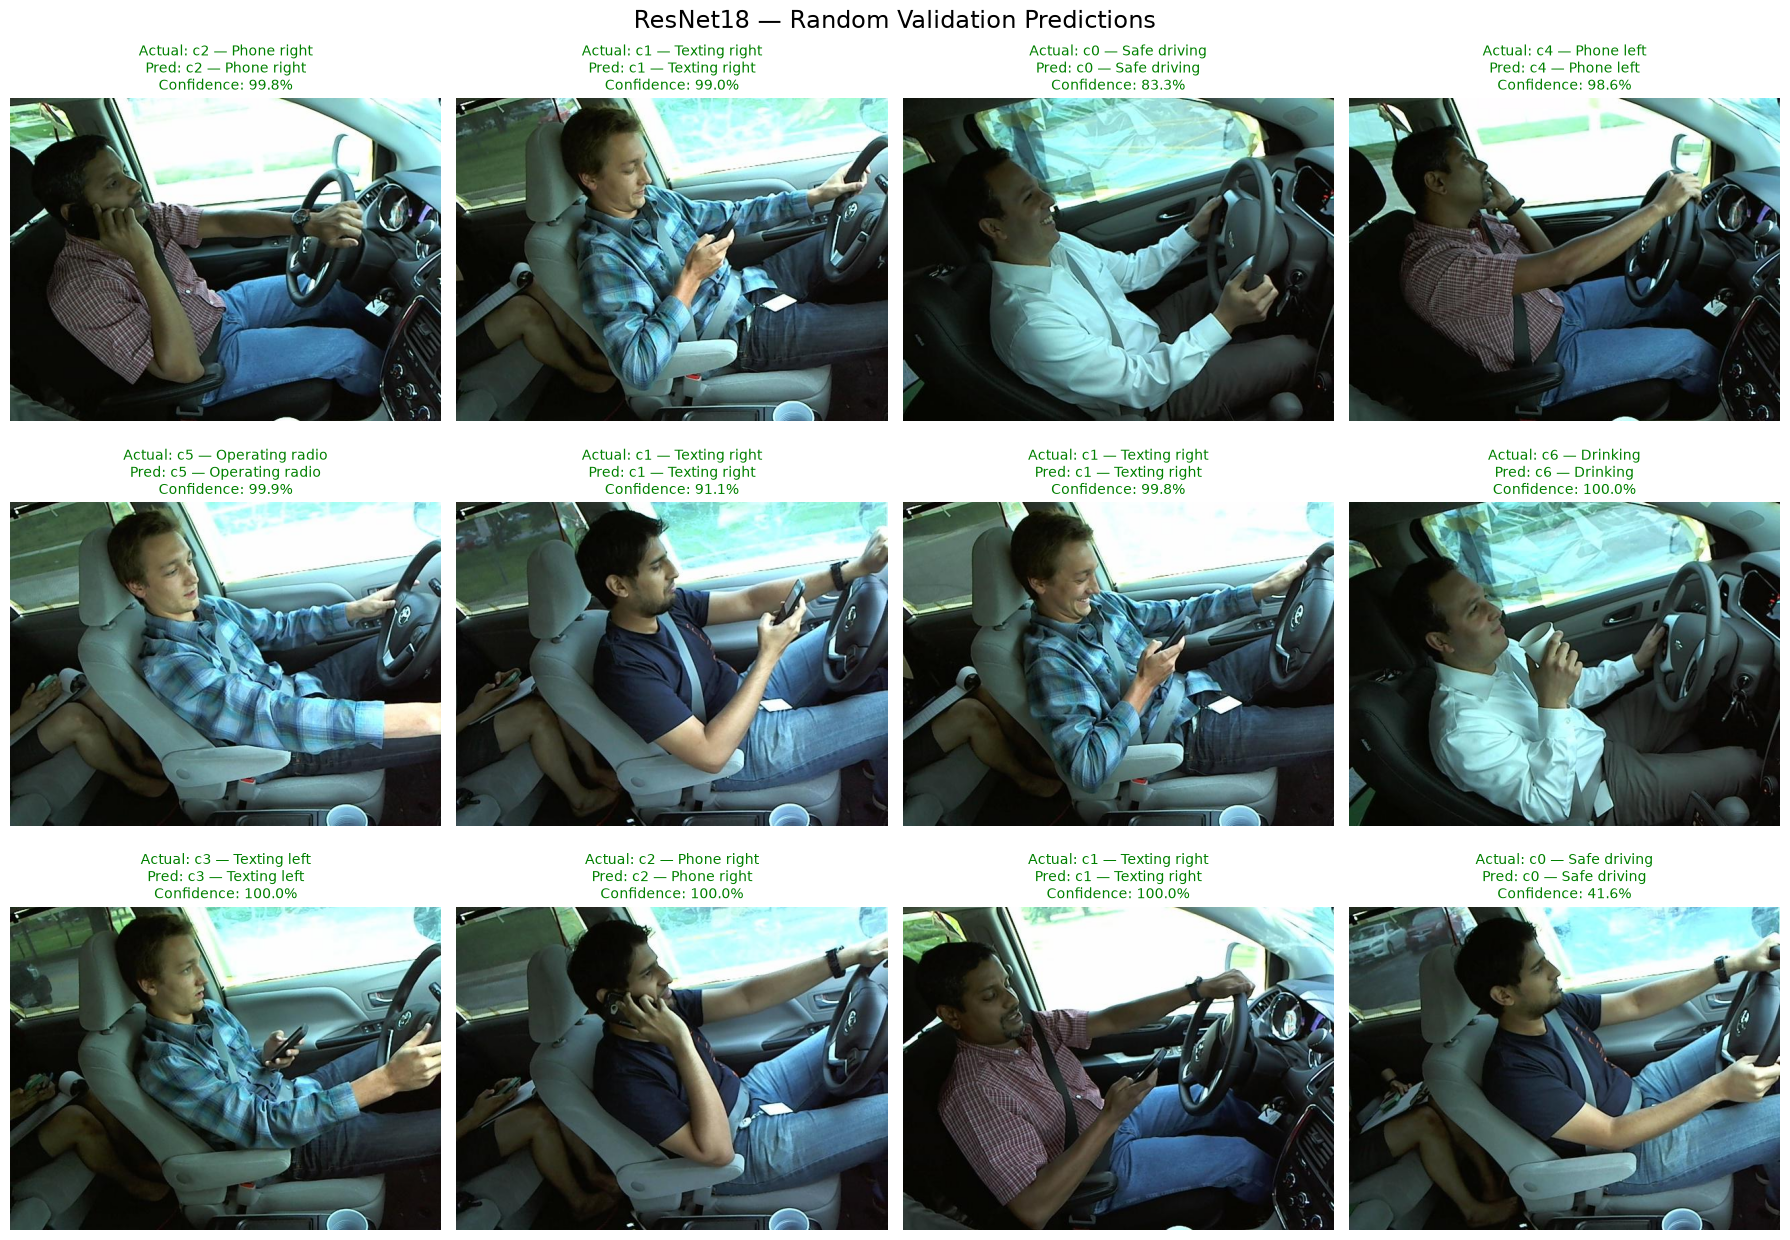

Images inspected: 12
Correct predictions: 12
Incorrect predictions: 0
Sample accuracy: 100.00%


In [9]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ==========================================
# 1. Configuration
# ==========================================

NUM_IMAGES = 12
RANDOM_SEED = 42

class_names = {
    "c0": "Safe driving",
    "c1": "Texting right",
    "c2": "Phone right",
    "c3": "Texting left",
    "c4": "Phone left",
    "c5": "Operating radio",
    "c6": "Drinking",
    "c7": "Reaching behind",
    "c8": "Hair/makeup",
    "c9": "Talking to passenger"
}

# ==========================================
# 2. Load our best fine-tuned ResNet18
# ==========================================

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

# ==========================================
# 3. Randomly select validation images
# ==========================================

samples = val_df.sample(
    n=NUM_IMAGES,
    random_state=RANDOM_SEED
)

original_images = []
input_tensors = []

for _, row in samples.iterrows():

    image_path = (
        image_root /
        row["classname"] /
        row["img"]
    )

    with Image.open(image_path) as img:
        original = img.convert("RGB")

    original_images.append(original)

    # Apply validation preprocessing
    input_tensors.append(
        val_transform(original)
    )

# Combine images into one batch
batch = torch.stack(input_tensors).to(device)

# ==========================================
# 4. Perform inference
# ==========================================

with torch.inference_mode():

    outputs = model(batch)

    probabilities = torch.softmax(
        outputs,
        dim=1
    )

    confidences, predictions = probabilities.max(dim=1)

predictions = predictions.cpu().numpy()
confidences = confidences.cpu().numpy()

# ==========================================
# 5. Display predictions
# ==========================================

fig, axes = plt.subplots(
    3, 4,
    figsize=(18, 13)
)

correct_count = 0

for i, (ax, (_, row)) in enumerate(
    zip(axes.flat, samples.iterrows())
):

    actual = row["classname"]
    predicted = f"c{predictions[i]}"

    correct = actual == predicted

    if correct:
        correct_count += 1

    color = "green" if correct else "red"

    ax.imshow(original_images[i])

    ax.set_title(
        f"Actual: {actual} — {class_names[actual]}\n"
        f"Pred: {predicted} — {class_names[predicted]}\n"
        f"Confidence: {confidences[i]:.1%}",
        color=color,
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "ResNet18 — Random Validation Predictions",
    fontsize=17
)

plt.tight_layout()
plt.show()

# ==========================================
# 6. Summary
# ==========================================

print("Images inspected:", NUM_IMAGES)
print("Correct predictions:", correct_count)
print("Incorrect predictions:", NUM_IMAGES - correct_count)
print(f"Sample accuracy: {correct_count / NUM_IMAGES:.2%}")

## 10. ResNet18 — Misclassified Validation Images

Visualize 12 incorrectly classified validation images.

Objectives:
- Compare actual and predicted activities.
- Examine prediction confidence.
- Include different drivers and error types.
- Identify possible reasons for misclassification.

Use the saved best ResNet18 checkpoint.

Total validation mistakes: 399


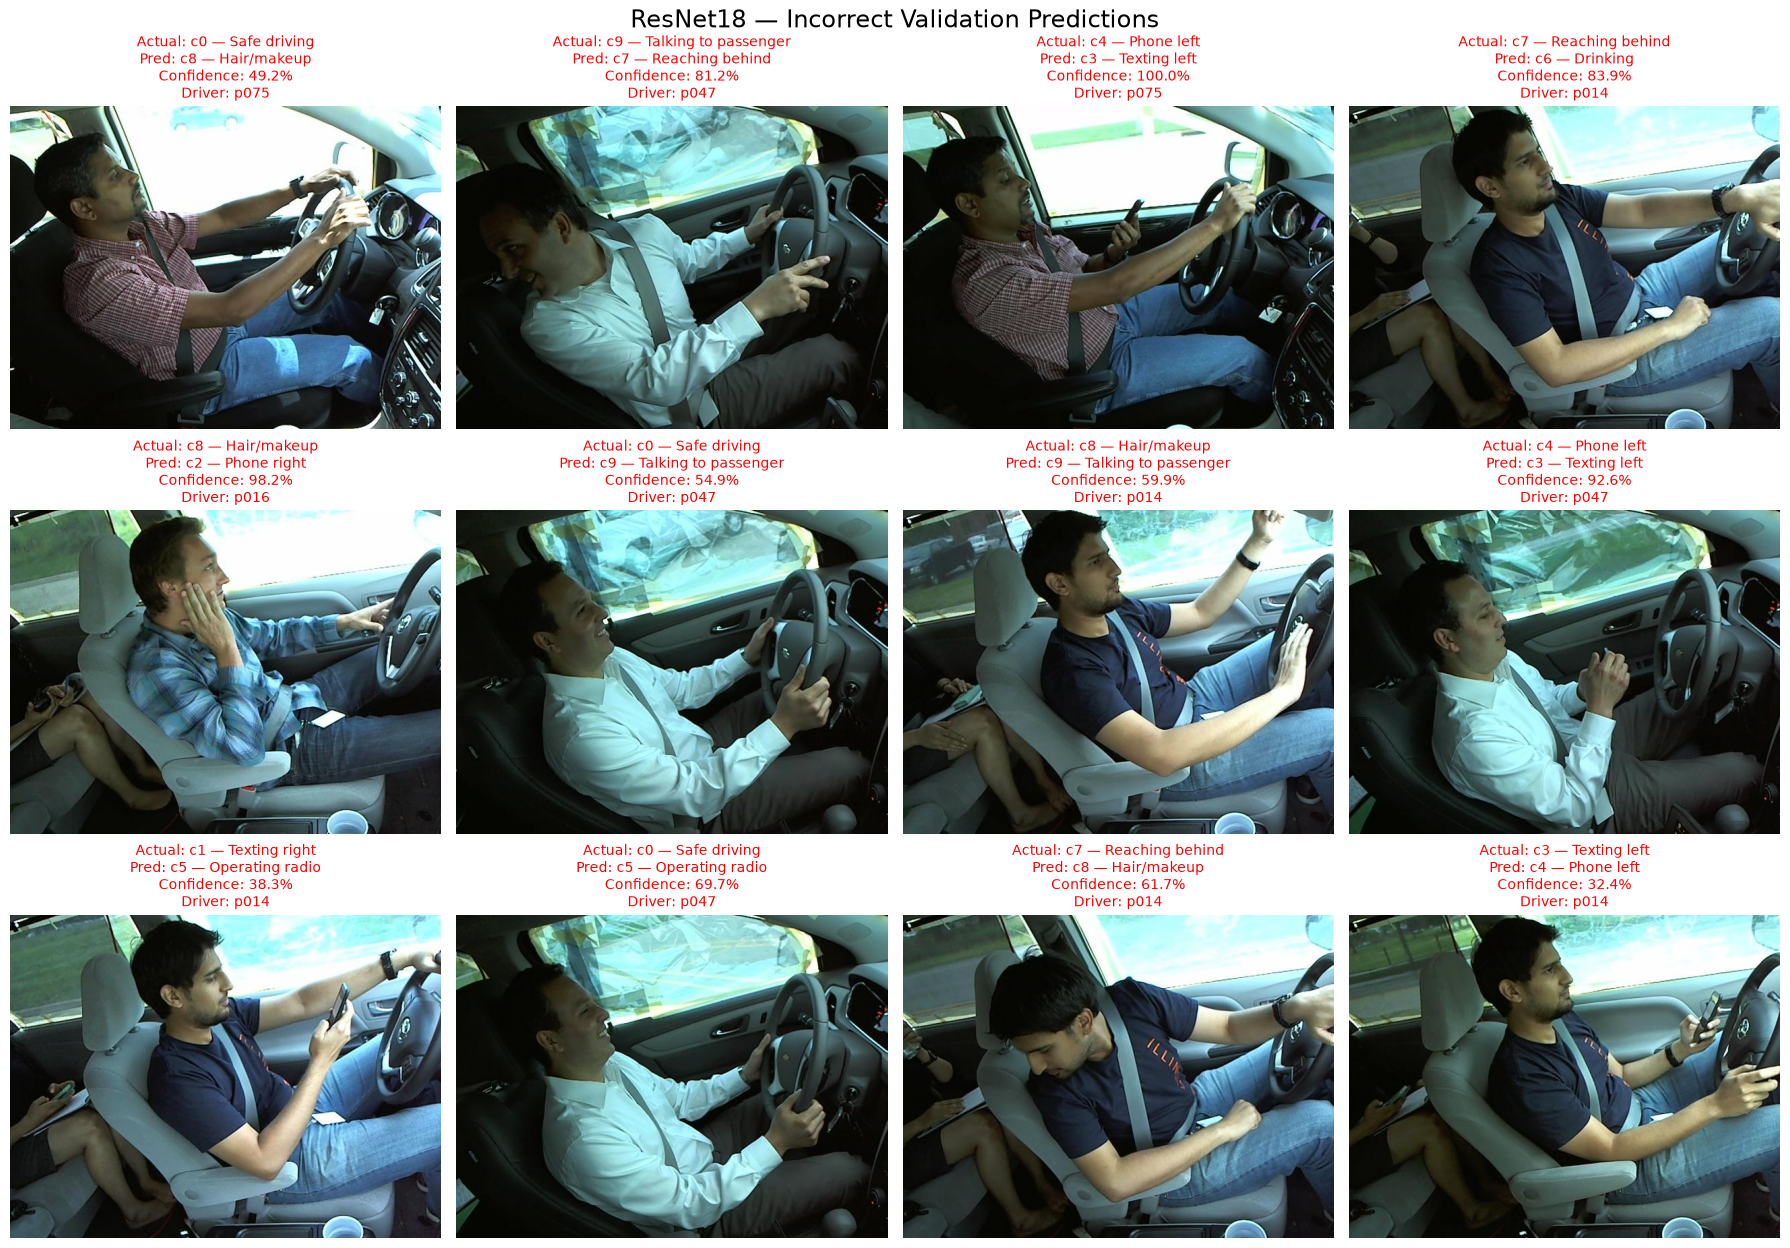

Incorrect examples displayed: 12
Figure saved!


In [10]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

# ==========================================
# 1. Select incorrect predictions
# ==========================================

mistakes = prediction_df[
    ~prediction_df["correct"]
].copy()

print("Total validation mistakes:", len(mistakes))

# Select different driver/class/confusion combinations
diverse_mistakes = (
    mistakes
    .groupby(
        ["subject", "classname", "predicted"],
        group_keys=False
    )
    .sample(n=1, random_state=42)
)

# Randomly choose 12 different error examples
samples = diverse_mistakes.sample(
    n=min(12, len(diverse_mistakes)),
    random_state=42
)

# ==========================================
# 2. Load best trained ResNet18
# ==========================================

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

# ==========================================
# 3. Load images
# ==========================================

original_images = []
input_tensors = []

for _, row in samples.iterrows():

    image_path = (
        image_root /
        row["classname"] /
        row["img"]
    )

    with Image.open(image_path) as img:
        original = img.convert("RGB")

    original_images.append(original)

    input_tensors.append(
        val_transform(original)
    )

batch = torch.stack(input_tensors).to(device)

# ==========================================
# 4. Run inference
# ==========================================

with torch.inference_mode():

    outputs = model(batch)

    probabilities = torch.softmax(outputs, dim=1)

    confidences, predictions = probabilities.max(dim=1)

predictions = predictions.cpu().numpy()
confidences = confidences.cpu().numpy()

# Verify predictions match the saved error analysis
assert all(
    f"c{pred}" == row["predicted"]
    for pred, (_, row) in zip(predictions, samples.iterrows())
)

# ==========================================
# 5. Visualize mistakes
# ==========================================

fig, axes = plt.subplots(3, 4, figsize=(18, 13))

for i, (ax, (_, row)) in enumerate(
    zip(axes.flat, samples.iterrows())
):

    actual = row["classname"]
    predicted = f"c{predictions[i]}"

    ax.imshow(original_images[i])

    ax.set_title(
        f"Actual: {actual} — {class_names[actual]}\n"
        f"Pred: {predicted} — {class_names[predicted]}\n"
        f"Confidence: {confidences[i]:.1%}\n"
        f"Driver: {row['subject']}",
        color="red",
        fontsize=10
    )

    ax.axis("off")

# Hide unused axes
for ax in axes.flat[len(samples):]:
    ax.axis("off")

plt.suptitle(
    "ResNet18 — Incorrect Validation Predictions",
    fontsize=17
)

plt.tight_layout()

# ==========================================
# 6. Save visualization
# ==========================================

plt.savefig(
    analysis_dir / "misclassified_examples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Incorrect examples displayed:", len(samples))
print("Figure saved!")